# 06 · Final test, money and a second industry

1. The model chosen in notebook 05 is refitted on train+valid (160k clients) and evaluated **once** on the test
   split (40,008 clients) that no earlier step has touched.
2. Is the predicted uplift calibrated? Are there "sleeping dogs" (clients the SMS hurts)?
3. Who are the clients the model wants to contact?
4. What is targeting worth in money, and how many clients should be contacted?
5. Does the same pipeline work in a different industry (online advertising, Criteo)?
6. The model is saved with a model card for the API (step 7).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from uplift import artifact
from uplift.business import Economics, best_policy, bootstrap_best_share, decile_table, profit_curve
from uplift.criteo import CRITEO_SPEC, load_criteo_sample
from uplift.features import load_model_table
from uplift.metrics import cv_evaluate, evaluate, qini_curve
from uplift.models import BASE_SPEC, ResponseModel, TLearner, selected_model

FIG = ROOT / "reports" / "figures"
df = load_model_table()
pool, test = df[df.split != "test"], df[df.split == "test"]
t, y = test.treatment_flg.to_numpy(), test.target.to_numpy()

model = selected_model().fit(pool, pool.treatment_flg, pool.target)
response = ResponseModel(spec=BASE_SPEC).fit(pool, pool.treatment_flg, pool.target)
scores = {
    "uplift model (T-learner)": model.predict_uplift(test),
    "response model": response.predict_uplift(test),
    "random": np.random.default_rng(0).random(len(test)),
}
ate = y[t == 1].mean() - y[t == 0].mean()
print(f"train {len(pool):,}  test {len(test):,}  test ATE {ate*100:+.2f} pp")

train 160,031  test 40,008  test ATE +3.32 pp


## 1. Test results (single evaluation, 500 paired bootstrap resamples)

In [2]:
rep = evaluate(scores, t, y, n_boot=500, reference="response model")
fmt = lambda m, c, s: f"{rep.metrics.loc[m, c]*s:.2f} [{rep.ci_low.loc[m, c]*s:.2f}, {rep.ci_high.loc[m, c]*s:.2f}]"
pd.DataFrame({
    "uplift in top 10% (pp)": [fmt(m, "uplift@10%", 100) for m in scores],
    "uplift in top 30% (pp)": [fmt(m, "uplift@30%", 100) for m in scores],
    "Qini ×1000": [fmt(m, "qini", 1000) for m in scores],
}, index=list(scores))

,uplift in top 10% (pp),uplift in top 30% (pp),Qini ×1000
uplift model (T-learner),"7.90 [4.82, 10.90]","5.35 [3.58, 7.21]","1.99 [0.75, 3.30]"
response model,"0.70 [-0.68, 2.14]","1.66 [0.54, 2.91]","-1.30 [-2.53, -0.00]"
random,"0.99 [-2.12, 4.09]","2.69 [0.93, 4.28]","-0.51 [-2.03, 0.85]"


In [3]:
print("difference to the response model (paired):")
rep.vs_reference.drop(index="response model")

difference to the response model (paired):


,uplift@10%,uplift@30%,qini
uplift model (T-learner),"+0.0720 [+0.0390, +0.1074]","+0.0368 [+0.0179, +0.0576]","+0.0033 [+0.0012, +0.0053]"
random,"+0.0028 [-0.0301, +0.0384]","+0.0103 [-0.0113, +0.0294]","+0.0008 [-0.0011, +0.0027]"


The cross-validated estimate in notebook 05 was Qini 3.37 and +10.4 pp in the top 10%. The test values are lower;
part of that is the usual optimism of picking the best of many configurations on the same folds, part is the
sampling noise of a 40k test set (its interval contains the CV value). The ranking is unchanged: **the uplift model
beats the response model with an interval that excludes zero, and the response model is no better than random.**

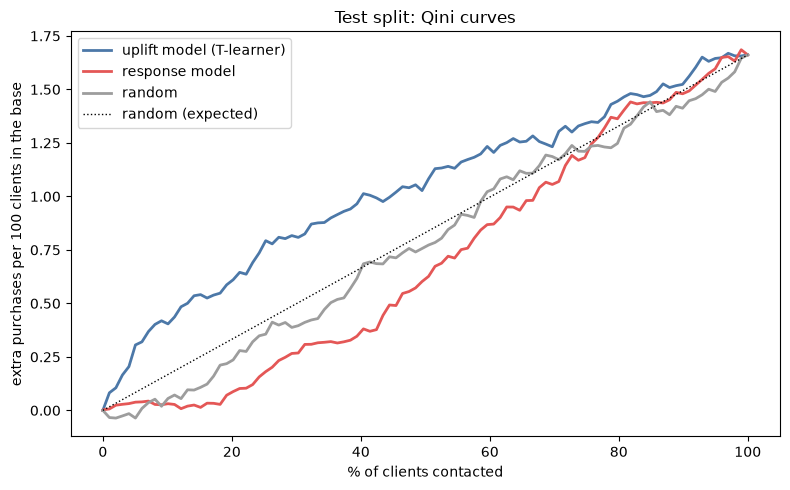

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
cols = {"uplift model (T-learner)": "#4C78A8", "response model": "#E45756", "random": "#9D9D9D"}
for name, s in scores.items():
    x, q = qini_curve(s, t, y)
    ax.plot(x * 100, q * 100, label=name, color=cols[name], lw=2)
ax.plot([0, 100], [0, q[-1] * 100], color="black", ls=":", lw=1, label="random (expected)")
ax.set_xlabel("% of clients contacted"); ax.set_ylabel("extra purchases per 100 clients in the base")
ax.set_title("Test split: Qini curves"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "06_qini_test.png", dpi=150); plt.show()

## 2. Calibration and sleeping dogs

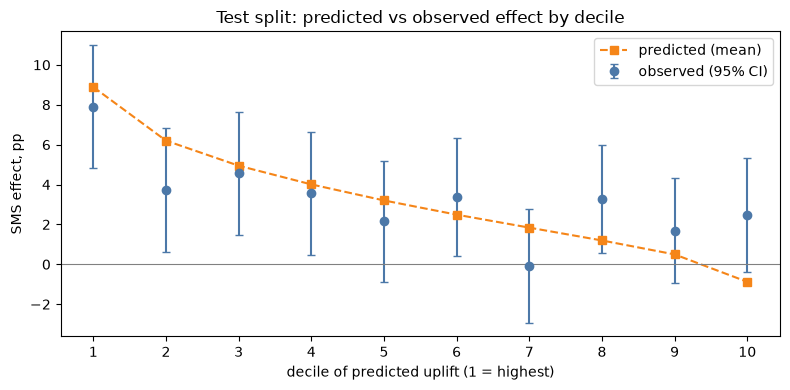

,clients,rate_without,rate_with,observed_uplift,ci_low,ci_high,predicted_uplift
decile,,,,,,,
1,4001,44.06,51.96,7.90,4.81,10.98,8.89
2,4001,47.75,51.49,3.73,0.63,6.83,6.20
3,4001,49.85,54.42,4.56,1.47,7.66,4.94
4,4001,53.82,57.38,3.57,0.49,6.64,4.01
5,4001,58.74,60.90,2.16,-0.88,5.19,3.20
6,4001,62.08,65.46,3.37,0.40,6.35,2.49
7,4001,70.15,70.06,-0.09,-2.92,2.75,1.84
8,4001,72.96,76.24,3.28,0.58,5.97,1.19
9,4000,75.47,77.14,1.67,-0.96,4.31,0.50


In [5]:
dec = decile_table(scores["uplift model (T-learner)"], t, y, predicted_uplift=scores["uplift model (T-learner)"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(dec.index, dec.observed_uplift * 100, yerr=[(dec.observed_uplift - dec.ci_low) * 100, (dec.ci_high - dec.observed_uplift) * 100],
            fmt="o", color="#4C78A8", capsize=3, label="observed (95% CI)")
ax.plot(dec.index, dec.predicted_uplift * 100, "s--", color="#F58518", label="predicted (mean)")
ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(dec.index)
ax.set_xlabel("decile of predicted uplift (1 = highest)"); ax.set_ylabel("SMS effect, pp")
ax.set_title("Test split: predicted vs observed effect by decile"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "06_calibration.png", dpi=150); plt.show()
pct = ["rate_without", "rate_with", "observed_uplift", "ci_low", "ci_high", "predicted_uplift"]
dec.assign(**{c: dec[c] * 100 for c in pct}).round(2)

* The top decile is predicted at about +9 pp and observed at about +8 pp; the order of the deciles is right.
* The predictions are **compressed at the bottom**: the model predicts negative effects for decile 10, but the
  observed effect there is positive. No decile shows a reliably negative effect, so **this campaign has no detectable
  "sleeping dogs"**. A claim that "the SMS hurts these clients" would not be supported by the data.
* For money calculations below, the observed treated-vs-control rates of each slice are used, not the predicted
  magnitudes.

## 3. Who does the model want to contact?

In [6]:
u = scores["uplift model (T-learner)"]
top = u >= np.quantile(u, 0.9)
def profile(g):
    return pd.Series({
        "median age": g["age"].median(),
        "median average basket": g["avg_basket"].median(),
        "median purchases in 4 months": g["n_transactions"].median(),
        "median days since last purchase": g["days_since_last_purchase"].median(),
        "median card age, days": g["card_age_days"].median(),
        "share who redeemed points": g["redeemed_before_campaign"].mean(),
        "share who used express points": (g["express_spent_trx"] > 0).mean(),
        "share women": (g["gender"].astype(str) == "F").mean(),
    })

pd.DataFrame({"top 10% by uplift": profile(test[top]), "everyone else": profile(test[~top])}).round(2)

,top 10% by uplift,everyone else
median age,62.00,43.00
median average basket,271.95,409.75
median purchases in 4 months,8.00,17.00
median days since last purchase,8.00,5.00
"median card age, days",208.00,509.00
share who redeemed points,0.68,0.82
share who used express points,0.27,0.17
share women,0.50,0.35


## 4. What is it worth? Profit curves

The dataset has no prices, so the economics are scenario inputs (currency units are arbitrary):

* **value** of one extra purchase = 100 (≈ 20% margin on the average basket of ~500),
* **SMS cost** = 2 per contact,
* **coupon** = 0 (plain SMS) or 10 (the SMS carries an offer redeemed by every contacted buyer).

Profit per 1,000 clients in the base when contacting the top-k share, estimated from the randomised test split:

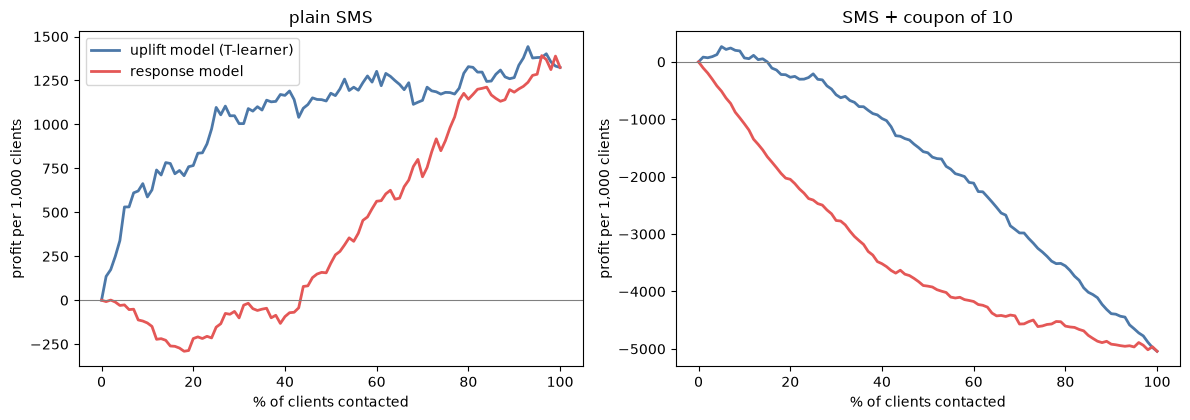

best share contacted  \
scenario           ranking                                          
plain SMS          uplift model (T-learner)                  0.93   
                   response model                            0.96   
SMS + coupon of 10 uplift model (T-learner)                  0.05   
                   response model                            0.00   

                                             profit at best share  \
scenario           ranking                                          
plain SMS          uplift model (T-learner)               1442.81   
                   response model                         1391.33   
SMS + coupon of 10 uplift model (T-learner)                266.07   
                   response model                            0.00   

                                             profit if everyone contacted  
scenario           ranking                                                 
plain SMS          uplift model (T-learner)                       1323.93  
                   response model                                 1323.93  
SMS + coupon of 10 uplift model (T-learner)                      -5041.35  
                   response model                                -5041.35

In [7]:
scenarios = {"plain SMS": Economics(100, 2, 0), "SMS + coupon of 10": Economics(100, 2, 10)}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
summary = []
for ax, (label, econ) in zip(axes, scenarios.items()):
    for name in ["uplift model (T-learner)", "response model"]:
        c = profit_curve(scores[name], t, y, econ)
        ax.plot(c.share_contacted * 100, c.profit_per_1000, color=cols[name], lw=2, label=name)
        b = best_policy(c)
        summary.append((label, name, b.share_contacted, b.profit_per_1000, c.iloc[-1].profit_per_1000))
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(label); ax.set_xlabel("% of clients contacted"); ax.set_ylabel("profit per 1,000 clients")
axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "06_profit_curves.png", dpi=150); plt.show()

pd.DataFrame(summary, columns=["scenario", "ranking", "best share contacted", "profit at best share", "profit if everyone contacted"]
            ).set_index(["scenario", "ranking"]).round(2)

In [8]:
shares = bootstrap_best_share(scores["uplift model (T-learner)"], t, y, scenarios["SMS + coupon of 10"], n_boot=200)
print(f"SMS + coupon: optimal share to contact, bootstrap median {np.median(shares):.0%}, "
      f"90% of resamples between {np.quantile(shares, 0.05):.0%} and {np.quantile(shares, 0.95):.0%}")

SMS + coupon: optimal share to contact, bootstrap median 5%, 90% of resamples between 5% and 9%


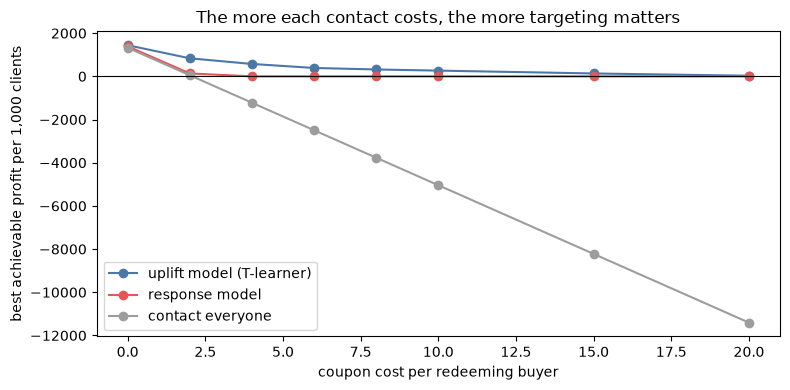

,uplift model (T-learner),response model,contact everyone
coupon,,,
0,1442.8,1391.3,1323.9
2,835.6,135.2,50.9
4,574.4,0.0,-1222.2
6,388.7,0.0,-2495.2
8,318.9,0.0,-3768.3
10,266.1,0.0,-5041.3
15,133.9,0.0,-8224.0
20,29.0,0.0,-11406.6


In [9]:
rows = []
for coupon in [0, 2, 4, 6, 8, 10, 15, 20]:
    econ = Economics(100, 2, coupon)
    row = {"coupon": coupon}
    for name in ["uplift model (T-learner)", "response model"]:
        row[name] = best_policy(profit_curve(scores[name], t, y, econ)).profit_per_1000
    row["contact everyone"] = econ.profit_per_contacted(y[t == 1].mean(), y[t == 0].mean()) * 1000
    rows.append(row)
sens = pd.DataFrame(rows).set_index("coupon")
fig, ax = plt.subplots(figsize=(8, 4))
for name, color in [("uplift model (T-learner)", "#4C78A8"), ("response model", "#E45756"), ("contact everyone", "#9D9D9D")]:
    ax.plot(sens.index, sens[name], "o-", color=color, label=name)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("coupon cost per redeeming buyer"); ax.set_ylabel("best achievable profit per 1,000 clients")
ax.set_title("The more each contact costs, the more targeting matters"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "06_profit_sensitivity.png", dpi=150); plt.show()
sens.round(1)

* **Plain SMS:** the average effect (+3.3 pp × 100 = 3.3 per client) already exceeds the SMS cost of 2, so contacting
  almost everyone is profitable; uplift targeting adds a modest gain by skipping the least responsive tail.
* **SMS with a coupon:** every contacted buyer redeems it, including the 60% who would have bought anyway, so
  contacting everyone loses money. The response model cannot fix this (its best option is to contact nobody),
  while **uplift targeting of a small top slice stays profitable**.
* The optimal share is uncertain (see the bootstrap range), so in production the recommendation is a range plus a
  holdout group to measure the real effect (step 8).

## 5. Second industry: online advertising (Criteo)

Same pipeline (logistic T-learner vs response model, same metrics) on a 3M-user random sample of Criteo Uplift v2.1:
randomised ad exposure (85% treated), 12 anonymised features, outcome = site visit. 70/30 train/test split.

In [10]:
crit = load_criteo_sample(3_000_000)
strata = crit.treatment_flg.astype(str) + crit.target.astype(str)
c_tr, c_te = train_test_split(crit, test_size=0.3, random_state=0, stratify=strata)
ct, cy = c_te.treatment_flg.to_numpy(), c_te.target.to_numpy()
c_scores = {
    "uplift model (T-learner)": TLearner(spec=CRITEO_SPEC).fit(c_tr, c_tr.treatment_flg, c_tr.target).predict_uplift(c_te),
    "response model": ResponseModel(spec=CRITEO_SPEC).fit(c_tr, c_tr.treatment_flg, c_tr.target).predict_uplift(c_te),
    "random": np.random.default_rng(0).random(len(c_te)),
}
print(f"Criteo test: {len(c_te):,} users, visit rate {cy.mean():.2%}, "
      f"ATE {(cy[ct == 1].mean() - cy[ct == 0].mean())*100:+.2f} pp ({cy[ct == 1].mean() / cy[ct == 0].mean() - 1:+.0%} relative)")
c_rep = evaluate(c_scores, ct, cy, n_boot=100, reference="response model")
pd.concat({"point": (c_rep.metrics * [100, 100, 1000]).round(2),
           "difference to response model [95% CI]": c_rep.vs_reference}, axis=1)

Criteo test: 900,000 users, visit rate 4.69%, ATE +1.04 pp (+27% relative)


point                   \
                         uplift@10% uplift@30%  qini   
uplift model (T-learner)       6.69       3.12  3.62   
response model                 5.57       2.93  3.02   
random                         0.79       0.83 -0.34   

                         difference to response model [95% CI]  \
                                                    uplift@10%   
uplift model (T-learner)            +0.0112 [+0.0041, +0.0181]   
response model                      +0.0000 [+0.0000, +0.0000]   
random                              -0.0478 [-0.0571, -0.0398]   

                                                      \
                                          uplift@30%   
uplift model (T-learner)  +0.0019 [+0.0003, +0.0035]   
response model            +0.0000 [+0.0000, +0.0000]   
random                    -0.0211 [-0.0241, -0.0180]   

                                                      
                                                qini  
uplift model (T-learner)  +0.0006 [+0.0002, +0.0009]  
response model            +0.0000 [+0.0000, +0.0000]  
random                    -0.0034 [-0.0039, -0.0030]

Here the response model is *not* useless: ad effects are concentrated among users who are likely to visit
anyway, so "likely visitors" and "persuadable visitors" overlap. The uplift model is still significantly better.
**The size of the gap is a property of the business**, which is why the evaluation must be done on a randomised
campaign rather than assumed:

| | Retail SMS (X5) | Online ads (Criteo) |
|---|---|---|
| Response model vs random | no better | much better |
| Uplift model vs response model | much better | better (significant) |

## 6. Save the model for the API

In [11]:
# The production artifact is written by the same code as scripts/train_final.py: it refits the model,
# adds the isotonic calibration (predicted -> observed effect on the test deciles) and the tier thresholds.
from uplift.train import train_and_save
meta = train_and_save()
restored = artifact.load()
assert np.allclose(restored.predict_uplift(test.head(1000)), model.predict_uplift(test.head(1000)))
{k: meta[k] for k in ("test_metrics", "calibration", "tier_thresholds")}

{'test_metrics': {'qini_x1000': 1.991,
  'uplift_top10_pp': 7.9,
  'uplift_top30_pp': 5.35,
  'test_ate_pp': 3.32},
 'calibration': {'x': [-0.008791,
   0.004957,
   0.011948,
   0.018383,
   0.024883,
   0.032019,
   0.040057,
   0.049431,
   0.061994,
   0.088864],
  'y': [0.018333,
   0.018333,
   0.018333,
   0.018333,
   0.02765,
   0.02765,
   0.035653,
   0.041477,
   0.041477,
   0.078979]},
 'tier_thresholds': {'high': 0.07045676260899542,
  'medium': 0.04418464184735771}}